# Zimbabwe House Listings: Cleaning and Exploratory Analysis

This notebook audits the scraped listings, removes repeat captures, prepares a USD target (all listing prices are in USD), handles missing property attributes, and summarizes the data. The source file is never overwritten. Generated tables and figures go to `reports/eda/`.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Work whether Jupyter starts in the repository root or notebooks/.
_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents] if (p / 'data' / 'houses.csv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find data/houses.csv in the current directory or its parents.')

DATA_PATH = PROJECT_ROOT / 'data' / 'houses.csv'
OUTPUT_DIR = PROJECT_ROOT / 'reports' / 'eda'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(DATA_PATH)
print(f'Loaded {len(raw):,} listings and {raw.shape[1]} columns from {DATA_PATH}')
display(raw.head(3))

Loaded 2,646 listings and 20 columns from C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\data\houses.csv


,listing_id,property_url,title,price_text,price_amount,currency,location_text,suburb,city,bedrooms,bathrooms,floor_area_m2,land_area_m2,property_type,description,amenities_json,photo_ids_json,photo_urls_json,photo_paths_json,collected_at_utc
0,259484,https://www.property.co.zw/for-sale/townhouses...,Modern 4 Bed Villas In Northwood,"$320,000",320000.0,USD,"Northwood, Harare North, Harare",Northwood,Harare,4.0,2.0,209.0,500.0,Townhouse Complex,Nostro and Mortgages welcome! Urban Flame is a...,"[""24hr Security"", ""Access Control"", ""Borehole""...","[""70fb44fe-7d3b-44f3-8767-ed78ff48b90a"", ""876a...","[""https://www.property.co.zw/uploadedfiles/70/...","[""images/259484_70fb44fe-7d3b-44f3-8767-ed78ff...",2026-11-22T11:03:30+00:00
1,259991,https://www.property.co.zw/for-sale/houses-pbo...,Waterfalls Uplands Property On 1 Acre For Sale...,"$230,000",230000.0,USD,"Waterfalls, Harare South, Harare",Waterfalls,Harare,3.0,2.0,287.8,4282.0,House,"Waterfalls, Uplands property for sale Ideal fo...","[""Fireplace"", ""Fitted Kitchen"", ""Flatlet/Cotta...","[""c478e138-03a8-44f1-a62a-b37766eb0371"", ""4602...","[""https://www.property.co.zw/uploadedfiles/c4/...","[""images/259991_c478e138-03a8-44f1-a62a-b37766...",2026-11-22T11:13:30+00:00
2,259146,https://www.property.co.zw/for-sale/houses-kwr...,"Thatched Duplex Retreat on 5,300 m² in Greenda...","$510,000",510000.0,USD,"Greendale North, Harare North, Harare",Greendale North,Harare,3.0,2.0,450.0,5300.0,House,Located near Arcturus close to Kamfinsa shops....,"[""Borehole"", ""Electric Gate"", ""Walled"", ""Water...","[""2f74e66c-3f5c-4d02-9817-b710e675dd93"", ""7148...","[""https://www.property.co.zw/uploadedfiles/2f/...","[""images/259146_2f74e66c-3f5c-4d02-9817-b710e6...",2026-11-22T11:13:34+00:00


## 1. Initial data quality audit

All listing prices are in USD. The source currency field is sometimes blank, so those prices are treated as USD as well; the field is normalized to `USD` in the cleaned data.

In [13]:
print('Shape:', raw.shape)
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_pct': (raw.isna().mean() * 100).round(1)}))
print('Exact duplicate rows:', int(raw.duplicated().sum()))
for key in ['listing_id', 'property_url']:
    print(f'Duplicate {key} values:', int(raw[key].duplicated(keep=False).sum()))
display(raw['currency'].fillna('(missing)').value_counts().rename_axis('currency').to_frame('listings'))
display(raw['price_text'].fillna('(missing)').value_counts().head(12).rename_axis('price_text').to_frame('listings'))

Shape: (2646, 20)


,dtype,missing,missing_pct
listing_id,int64,0,0.0
property_url,str,0,0.0
title,str,0,0.0
price_text,str,4,0.2
price_amount,float64,17,0.6
currency,str,1897,71.7
location_text,str,4,0.2
suburb,str,4,0.2
city,str,4,0.2
bedrooms,float64,3,0.1


Exact duplicate rows: 0
Duplicate listing_id values: 0
Duplicate property_url values: 22


,listings
currency,
(missing),1897
USD,749


,listings
price_text,
"$250,000",77
"$150,000",74
"$450,000",58
"$160,000",58
"$130,000",56
"$220,000",54
"$550,000",53
"$350,000",52
"$180,000",51


## 2. Deduplicate and normalize the target

Repeated URLs are repeat captures of a listing. Keep the latest capture. All listing prices are USD, regardless of whether the source currency field is populated, so normalize the cleaned currency field to `USD`. Listings with no usable positive price stay in the cleaned listing export but are excluded from the USD analysis/model dataset.

In [14]:
clean = raw.copy()
clean['_source_order'] = np.arange(len(clean))
clean['collected_at_utc'] = pd.to_datetime(clean['collected_at_utc'], errors='coerce', utc=True)
clean = clean.sort_values(['property_url', 'collected_at_utc', '_source_order'])
clean = clean.drop_duplicates('property_url', keep='last').copy()
clean = clean.sort_values('_source_order').drop(columns='_source_order').reset_index(drop=True)
clean['currency'] = 'USD'

clean['price_amount'] = pd.to_numeric(clean['price_amount'], errors='coerce')
# Recover a missing numeric amount from digits in the source text.
text_amount = pd.to_numeric(
    clean['price_text'].astype('string').str.replace(',', '', regex=False).str.extract('([0-9]+(?:[.][0-9]+)?)', expand=False),
    errors='coerce',
)
clean['price_amount'] = clean['price_amount'].fillna(text_amount)
clean['price_usd'] = clean['price_amount'].where(clean['price_amount'].gt(0))

property_numeric = ['bedrooms', 'bathrooms', 'floor_area_m2', 'land_area_m2']
for column in property_numeric:
    clean[column] = pd.to_numeric(clean[column], errors='coerce')
    clean.loc[clean[column] <= 0, column] = np.nan

clean.to_csv(OUTPUT_DIR / 'cleaned_listings.csv', index=False)
usd = clean.loc[clean['price_usd'].notna()].copy()
print(f'Listings after URL deduplication: {len(clean):,} (removed {len(raw) - len(clean):,})')
print(f'Listings with a positive USD price: {len(usd):,}')
print(f'Listings with no usable positive price: {len(clean) - len(usd):,}')
display(clean['currency'].fillna('(unknown)').value_counts().rename_axis('currency').to_frame('listings'))

Listings after URL deduplication: 2,635 (removed 11)
Listings with a positive USD price: 2,618
Listings with no usable positive price: 17


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12988\895899297.py:15: Pandas4Warning: 'IntegerArray' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  clean['price_amount'] = clean['price_amount'].fillna(text_amount)


,listings
currency,
USD,2635


## 3. Missing values and outliers

Zero/nonpositive bedroom, bathroom, and area values are treated as missing. IQR fences are used to flag unusual numeric values, not automatically delete them: expensive or large properties can be legitimate. Medians by property type (then the overall median) are used only in the separate model-ready USD copy; cleaned listings retain missing attributes.

In [15]:
numeric_for_analysis = ['price_usd', *property_numeric]
missingness = pd.DataFrame({
    'missing': clean.isna().sum(),
    'missing_pct': (clean.isna().mean() * 100).round(1),
}).sort_values('missing_pct', ascending=False)
missingness.to_csv(OUTPUT_DIR / 'missingness.csv')

def iqr_bounds(series):
    values = series.dropna()
    if values.empty:
        return np.nan, np.nan
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - 1.5 * spread, q3 + 1.5 * spread

outlier_summary = []
for column in numeric_for_analysis:
    low, high = iqr_bounds(usd[column])
    flag = f'outlier_{column}'
    usd[flag] = usd[column].lt(low) | usd[column].gt(high)
    outlier_summary.append({'feature': column, 'lower_fence': low, 'upper_fence': high,
                            'flagged_count': int(usd[flag].sum())})
outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary.to_csv(OUTPUT_DIR / 'outlier_summary.csv', index=False)

# Impute only the model-ready copy; the cleaned listing export above remains un-imputed.
model_ready = usd.copy()
model_ready['property_type'] = model_ready['property_type'].fillna('Unknown')
for column in property_numeric:
    by_type = model_ready.groupby('property_type')[column].transform('median')
    model_ready[column] = model_ready[column].fillna(by_type)
    model_ready[column] = model_ready[column].fillna(model_ready[column].median())
model_ready.to_csv(OUTPUT_DIR / 'usd_model_ready.csv', index=False)

display(missingness.head(15))
display(outlier_summary)
print('Missing property attributes remaining in model-ready data:')
display(model_ready[property_numeric].isna().sum().rename('missing').to_frame())

,missing,missing_pct
floor_area_m2,329,12.5
bathrooms,288,10.9
land_area_m2,54,2.0
price_usd,17,0.6
price_amount,17,0.6
suburb,4,0.2
city,4,0.2
description,4,0.2
price_text,4,0.2
location_text,4,0.2


,feature,lower_fence,upper_fence,flagged_count
0,price_usd,-350000.0,850000.0,149
1,bedrooms,0.0,8.0,24
2,bathrooms,0.5,4.5,228
3,floor_area_m2,-300.0,980.0,255
4,land_area_m2,-4125.0,8075.0,155


Missing property attributes remaining in model-ready data:


,missing
bedrooms,0
bathrooms,0
floor_area_m2,0
land_area_m2,0


## 4. Summary tables

Prices are summarized for listings with a usable positive USD price. Means are shown alongside medians and quantiles because asking prices are typically skewed.

In [16]:
currency_eligibility = clean.assign(usd_eligible=clean['price_usd'].notna()).groupby('currency', dropna=False).agg(
    listings=('property_url', 'size'), usd_eligible=('usd_eligible', 'sum')
).reset_index()
currency_eligibility['currency'] = currency_eligibility['currency'].fillna('(unknown)')
city_summary = usd.groupby('city', dropna=False).agg(
    listings=('price_usd', 'size'), median_price_usd=('price_usd', 'median'),
    mean_price_usd=('price_usd', 'mean'), q25_price_usd=('price_usd', lambda s: s.quantile(.25)),
    q75_price_usd=('price_usd', lambda s: s.quantile(.75)),
).sort_values('listings', ascending=False).reset_index()
property_type_summary = usd.groupby('property_type', dropna=False).agg(
    listings=('price_usd', 'size'), median_price_usd=('price_usd', 'median'),
    mean_price_usd=('price_usd', 'mean'), q25_price_usd=('price_usd', lambda s: s.quantile(.25)),
    q75_price_usd=('price_usd', lambda s: s.quantile(.75)),
).sort_values('listings', ascending=False).reset_index()
price_summary = usd['price_usd'].describe(percentiles=[.1, .25, .5, .75, .9]).rename('price_usd').to_frame()
numeric_summary = usd[numeric_for_analysis].describe(percentiles=[.1, .25, .5, .75, .9]).T

for name, table in [('currency_eligibility', currency_eligibility), ('city_summary', city_summary),
                    ('property_type_summary', property_type_summary)]:
    table.to_csv(OUTPUT_DIR / f'{name}.csv', index=False)
price_summary.to_csv(OUTPUT_DIR / 'price_summary_usd.csv')
numeric_summary.to_csv(OUTPUT_DIR / 'numeric_summary_usd.csv')

display(currency_eligibility)
display(price_summary)
display(city_summary.head(15))
display(property_type_summary.head(15))
display(numeric_summary)

,currency,listings,usd_eligible
0,USD,2635,2618


,price_usd
count,2618.0
mean,312234.877005
std,381639.994017
min,110.0
10%,50000.0
25%,100000.0
50%,198000.0
75%,400000.0
90%,650000.0
max,7500000.0


,city,listings,median_price_usd,mean_price_usd,q25_price_usd,q75_price_usd
0,Harare,1908,240000.0,360116.77044,125000.0,450000.0
1,Bulawayo,285,180000.0,217557.894737,120000.0,250000.0
2,Mashonaland,174,65000.0,160017.241379,40000.0,150000.0
3,Mashonaland East,104,97000.0,101121.25,56500.0,140000.0
4,Matabeleland,42,215000.0,289666.666667,105000.0,493750.0
5,Manicaland,33,220000.0,236242.424242,125000.0,350000.0
6,Mashonaland West,29,120000.0,131672.413793,90000.0,150000.0
7,Midlands Province,29,100000.0,118379.310345,42000.0,145000.0
8,Masvingo Province,9,185000.0,196111.111111,35000.0,220000.0
9,Regional,5,116000.0,197200.0,110000.0,120000.0


,property_type,listings,median_price_usd,mean_price_usd,q25_price_usd,q75_price_usd
0,House,2310,185000.0,312283.899567,95000.0,400000.0
1,Townhouse,208,235000.0,294663.942308,140000.0,350000.0
2,Townhouse Complex,84,250000.0,354321.428571,171250.0,337500.0
3,8 Unit Townhouse Complex,4,487500.0,455000.0,362500.0,580000.0
4,2 Unit Townhouse Complex,3,350000.0,355000.0,242500.0,465000.0
5,6 Unit Townhouse Complex,2,350000.0,350000.0,350000.0,350000.0
6,19 Unit Townhouse Complex,1,125000.0,125000.0,125000.0,125000.0
7,17 Unit Townhouse Complex,1,330000.0,330000.0,330000.0,330000.0
8,13 Unit Townhouse Complex,1,110000.0,110000.0,110000.0,110000.0
9,12 Unit Townhouse Complex,1,217000.0,217000.0,217000.0,217000.0


,count,mean,std,min,10%,25%,50%,75%,90%,max
price_usd,2618.0,312234.877005,381639.994017,110.0,50000.0,100000.0,198000.0,400000.0,650000.0,7500000.0
bedrooms,2615.0,4.112428,1.659056,1.0,3.0,3.0,4.0,5.0,6.0,42.0
bathrooms,2332.0,2.660806,3.420275,1.0,1.0,2.0,2.0,3.0,4.0,150.0
floor_area_m2,2295.0,1621.341307,42431.261918,1.0,100.0,180.0,300.0,500.0,1000.0,2023430.0
land_area_m2,2568.0,44055.048364,2076124.291796,1.0,300.0,450.0,1250.0,3500.0,5253.4,105210000.0


## 5. Plots

Price axes use logarithmic scaling where useful to make the long-tailed distribution readable. Figures are saved as PNG files in `reports/eda/`.

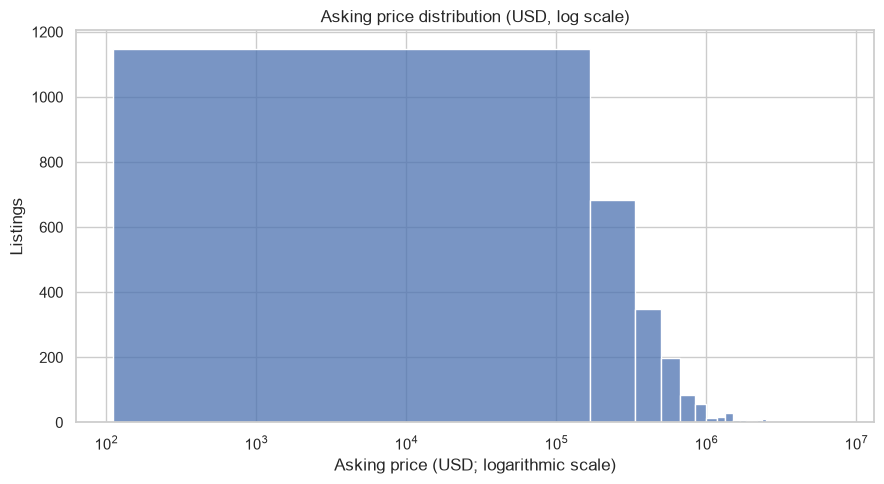

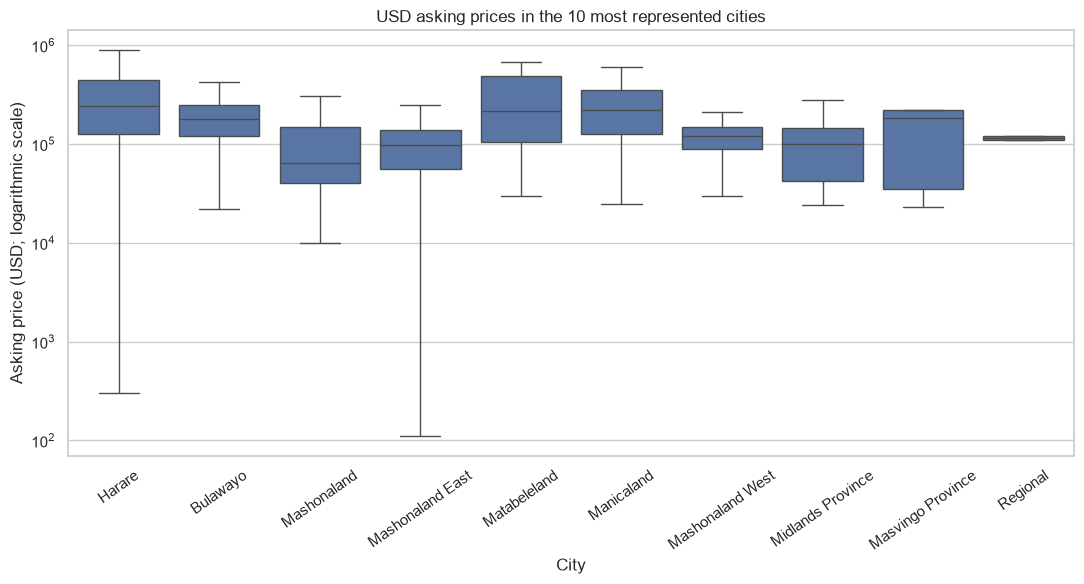

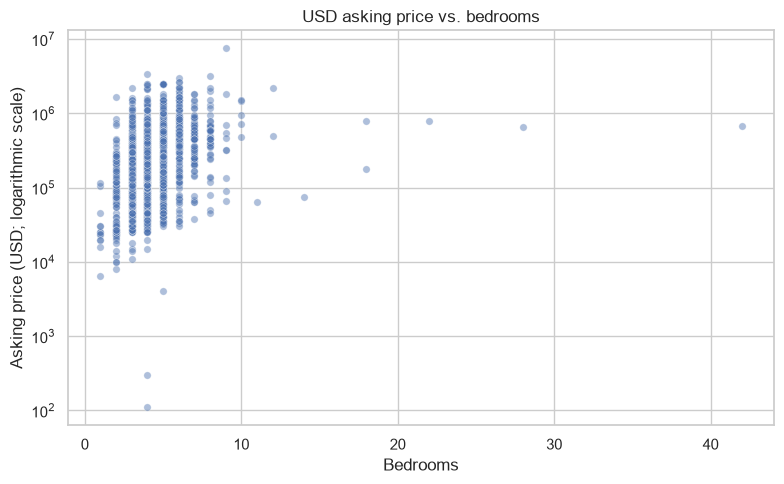

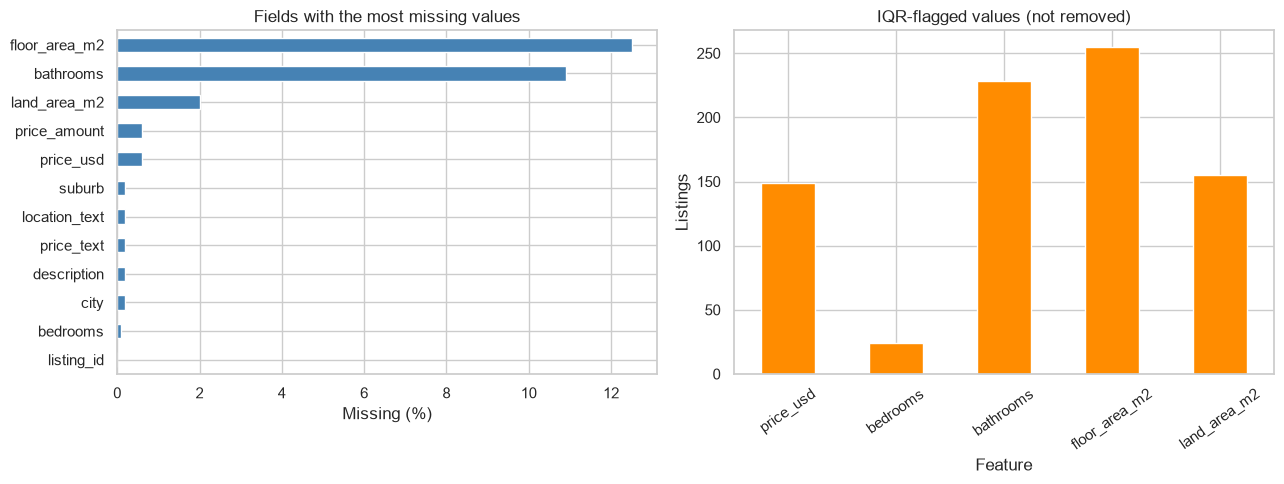

In [17]:
sns.set_theme(style='whitegrid')

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=usd, x='price_usd', bins=45, ax=ax)
ax.set_xscale('log')
ax.set(title='Asking price distribution (USD, log scale)', xlabel='Asking price (USD; logarithmic scale)', ylabel='Listings')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'usd_price_distribution.png', dpi=160)
plt.show()

city_order = usd['city'].value_counts().head(10).index.tolist()
city_data = usd.loc[usd['city'].isin(city_order)]
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=city_data, x='city', y='price_usd', order=city_order, showfliers=False, ax=ax)
ax.set_yscale('log')
ax.set(title='USD asking prices in the 10 most represented cities', xlabel='City', ylabel='Asking price (USD; logarithmic scale)')
ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'usd_price_by_city.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=usd, x='bedrooms', y='price_usd', alpha=.45, s=28, ax=ax)
ax.set_yscale('log')
ax.set(title='USD asking price vs. bedrooms', xlabel='Bedrooms', ylabel='Asking price (USD; logarithmic scale)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'usd_price_vs_bedrooms.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
missingness.head(12).sort_values('missing_pct').plot.barh(y='missing_pct', legend=False, ax=axes[0], color='steelblue')
axes[0].set(title='Fields with the most missing values', xlabel='Missing (%)', ylabel='')
outlier_summary.set_index('feature')['flagged_count'].plot.bar(ax=axes[1], color='darkorange')
axes[1].set(title='IQR-flagged values (not removed)', xlabel='Feature', ylabel='Listings')
axes[1].tick_params(axis='x', rotation=35)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'data_quality_summary.png', dpi=160)
plt.show()

## 6. Data-derived findings and limitations

The values below are computed from the current input when the notebook is run. Read the price availability and missingness tables before modeling; listings with no usable positive price are excluded from price analyses. The IQR flags identify review candidates, not errors; check descriptions and source pages before excluding any high-priced or large property. Median imputation is a baseline for modeling, not a claim about the true missing value.

In [18]:
if usd.empty:
    print('No listings have a usable positive USD asking price; USD summaries and plots cannot be interpreted.')
else:
    print(f'Unique listings after URL deduplication: {len(clean):,}')
    print(f'Listings with a usable positive USD price: {len(usd):,} ({len(usd) / len(clean):.1%} of deduplicated listings)')
    print(f'Median USD asking price: ${usd["price_usd"].median():,.0f}')
    print(f'Mean USD asking price: ${usd["price_usd"].mean():,.0f}')
    print(f'USD price range: ${usd["price_usd"].min():,.0f}–${usd["price_usd"].max():,.0f}')
    print('Most represented city:', city_summary.iloc[0]['city'], f'({int(city_summary.iloc[0]["listings"]):,} USD listings)')
    print('Largest IQR-flagged feature count:', outlier_summary.sort_values('flagged_count', ascending=False).iloc[0].to_dict())
print(f'Outputs saved to: {OUTPUT_DIR}')

Unique listings after URL deduplication: 2,635
Listings with a usable positive USD price: 2,618 (99.4% of deduplicated listings)
Median USD asking price: $198,000
Mean USD asking price: $312,235
USD price range: $110–$7,500,000
Most represented city: Harare (1,908 USD listings)
Largest IQR-flagged feature count: {'feature': 'floor_area_m2', 'lower_fence': -300.0, 'upper_fence': 980.0, 'flagged_count': 255}
Outputs saved to: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\reports\eda
